In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

df = pd.read_csv("penguins_size.csv")
TARGET = "species"

print("Ukuran data:", df.shape)
display(df.head())

Ukuran data: (344, 7)


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   culmen_length_mm   342 non-null    float64
 3   culmen_depth_mm    342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


In [3]:
print("Missing value per kolom:")
display(df.isna().sum()[df.isna().sum() > 0].to_frame("jumlah"))
print("Duplikat baris:", df.duplicated().sum())

for col in ["species", "island", "sex"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

# Baris dengan semua ukuran kosong, dan nilai aneh pada kolom sex
ukuran = ["culmen_length_mm", "culmen_depth_mm", "flipper_length_mm", "body_mass_g"]
print("\nBaris tanpa ukuran sama sekali:")
display(df[df[ukuran].isna().all(axis=1)])
print("Baris dengan sex = '.':")
display(df[df["sex"] == "."])

display(df.describe().T.round(2))

Missing value per kolom:


,jumlah
culmen_length_mm,2
culmen_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,10


Duplikat baris: 0

species:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

island:
island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64

sex:
sex
MALE      168
FEMALE    165
NaN        10
.           1
Name: count, dtype: int64

Baris tanpa ukuran sama sekali:


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


Baris dengan sex = '.':


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
336,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,.


,count,mean,std,min,25%,50%,75%,max
culmen_length_mm,342.0,43.92,5.46,32.1,39.22,44.45,48.5,59.6
culmen_depth_mm,342.0,17.15,1.97,13.1,15.60,17.30,18.7,21.5
flipper_length_mm,342.0,200.92,14.06,172.0,190.00,197.00,213.0,231.0
body_mass_g,342.0,4201.75,801.95,2700.0,3550.00,4050.00,4750.0,6300.0


Jumlah kelas: 3


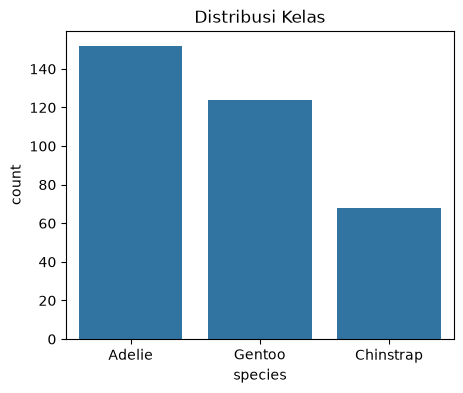

In [4]:
jumlah = df[TARGET].value_counts()
print("Jumlah kelas:", df[TARGET].nunique())
plt.figure(figsize=(5, 4))
sns.countplot(x=TARGET, data=df, order=jumlah.index)
plt.title("Distribusi Kelas")
plt.show()

In [5]:
df = df.copy()

# Nilai "." pada sex bukan data valid, jadikan missing value
df["sex"] = df["sex"].replace(".", np.nan)

# Buang baris yang semua ukuran tubuhnya kosong (tidak ada informasi untuk memprediksi)
df = df.dropna(subset=ukuran, how="all").reset_index(drop=True)

print("Ukuran data setelah dibersihkan:", df.shape)
print(df[TARGET].value_counts())

Ukuran data setelah dibersihkan: (342, 7)
species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64


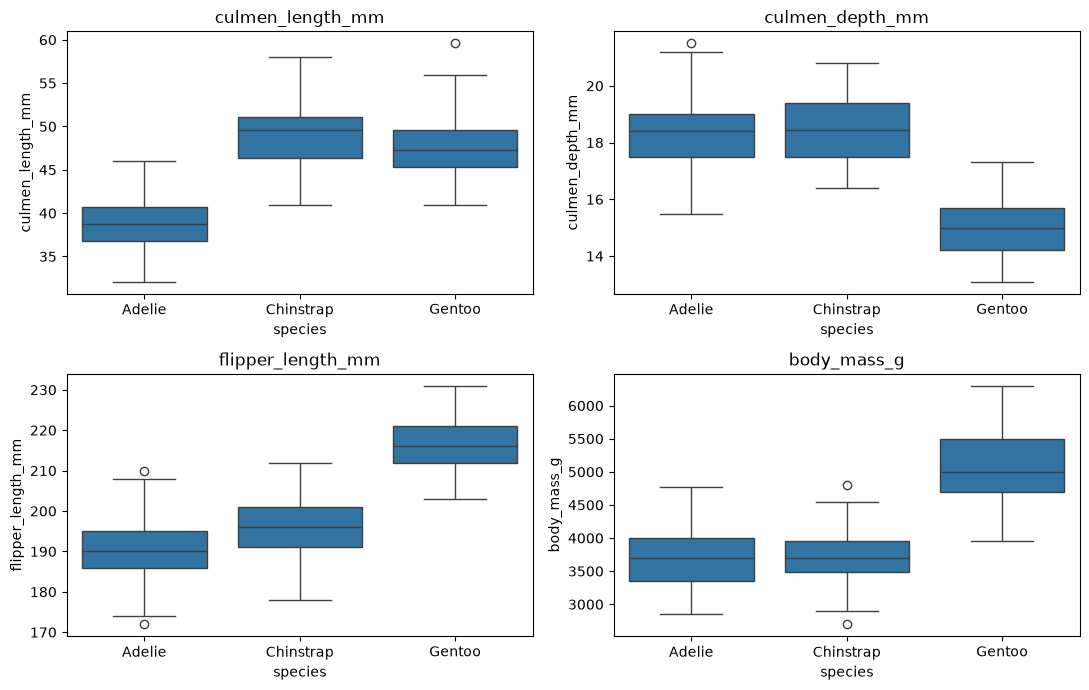

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), ukuran):
    sns.boxplot(x=TARGET, y=col, data=df, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

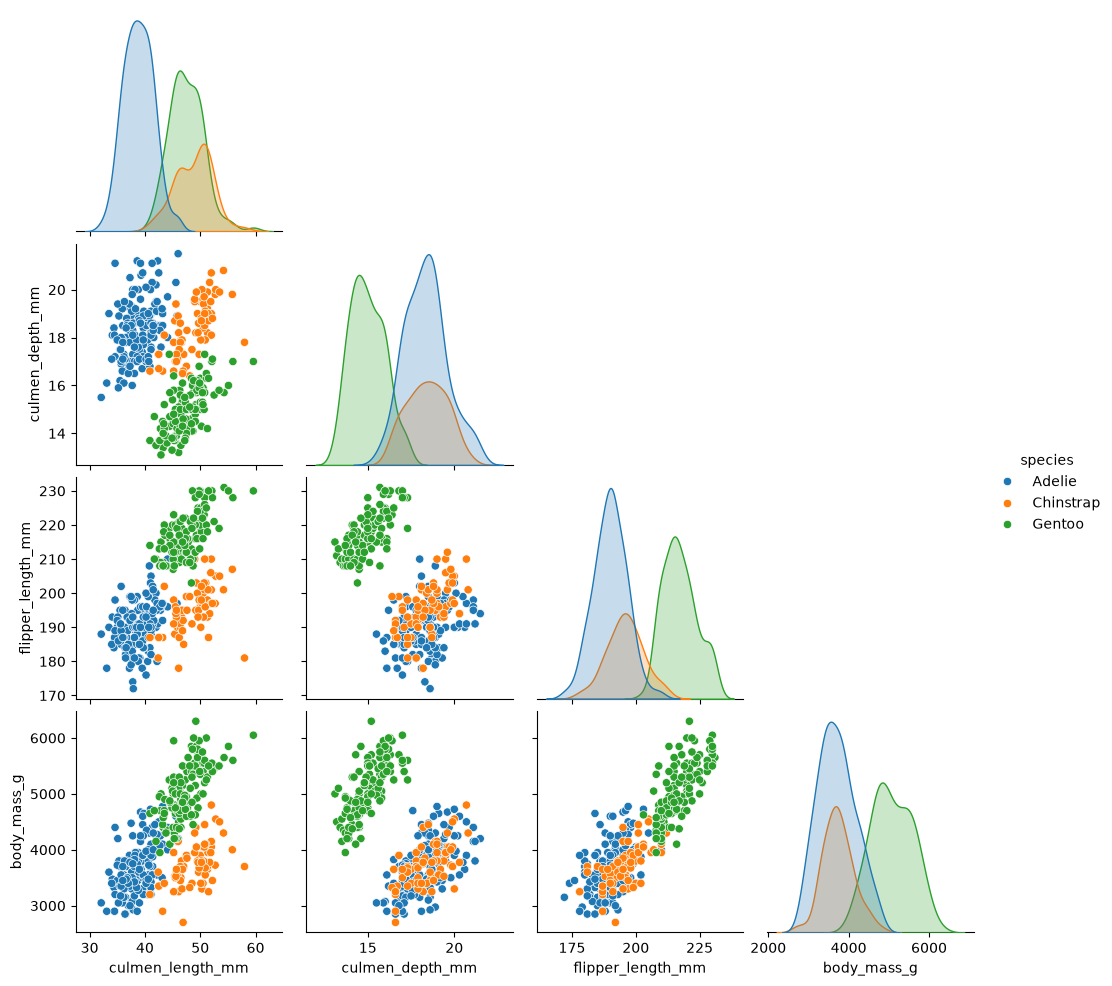

Jumlah spesies per pulau:


island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,51
Chinstrap,0,68,0
Gentoo,123,0,0


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.8,18.3,190.0,3700.7
Chinstrap,48.8,18.4,195.8,3733.1
Gentoo,47.5,15.0,217.2,5076.0


In [7]:
sns.pairplot(df, hue=TARGET, vars=ukuran, corner=True)
plt.show()

print("Jumlah spesies per pulau:")
display(pd.crosstab(df["species"], df["island"]))
display(df.groupby("species")[ukuran].mean().round(1))

In [8]:
X = df.drop(columns=TARGET)
le = LabelEncoder()
y = pd.Series(le.fit_transform(df[TARGET]), index=df.index)
nama_kelas = list(le.classes_)

print("Pemetaan label:")
for i, k in enumerate(nama_kelas):
    print(f"  {i} -> {k}")

num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print("\nNumerik    :", num_cols)
print("Kategorikal:", cat_cols)

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("\nTrain:", X_train.shape, "| Test:", X_test.shape)

Pemetaan label:
  0 -> Adelie
  1 -> Chinstrap
  2 -> Gentoo

Numerik    : ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']
Kategorikal: ['island', 'sex']

Train: (273, 6) | Test: (69, 6)


In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=3000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "SVM": SVC(probability=True, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "roc_auc_ovr"]

rows = []
for nama, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", model)])
    hasil = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"Model": nama, **{m: hasil[f"test_{m}"].mean() for m in scoring}})

hasil_cv = pd.DataFrame(rows).set_index("Model").round(4).sort_values("f1_macro", ascending=False)
display(hasil_cv)

,accuracy,precision_macro,recall_macro,f1_macro,roc_auc_ovr
Model,,,,,
SVM,0.9963,0.9973,0.9939,0.9955,0.9998
Logistic Regression,0.9927,0.9947,0.9879,0.9909,0.9998
Random Forest,0.9890,0.9862,0.9885,0.9869,0.9996
Gradient Boosting,0.9890,0.9891,0.9851,0.9866,0.9995
KNN,0.9853,0.9801,0.9857,0.9826,0.9997
Decision Tree,0.9597,0.9602,0.9551,0.9547,0.9672


In [10]:
fitted, rows = {}, []
for nama, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("clf", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)
    fitted[nama] = pipe
    rows.append({
        "Model": nama,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, pred, average="macro", zero_division=0),
        "ROC-AUC (OvR)": roc_auc_score(y_test, proba, multi_class="ovr", average="macro"),
    })

hasil_test = pd.DataFrame(rows).set_index("Model").round(4).sort_values("F1 (macro)", ascending=False)
display(hasil_test)

,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (OvR)
Model,,,,,
Logistic Regression,1.0000,1.0000,1.0000,1.0000,1.0000
KNN,1.0000,1.0000,1.0000,1.0000,1.0000
SVM,1.0000,1.0000,1.0000,1.0000,1.0000
Random Forest,1.0000,1.0000,1.0000,1.0000,1.0000
Gradient Boosting,1.0000,1.0000,1.0000,1.0000,1.0000
Decision Tree,0.9855,0.9778,0.9889,0.9829,0.9914


Model terbaik: Logistic Regression
              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        30
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69



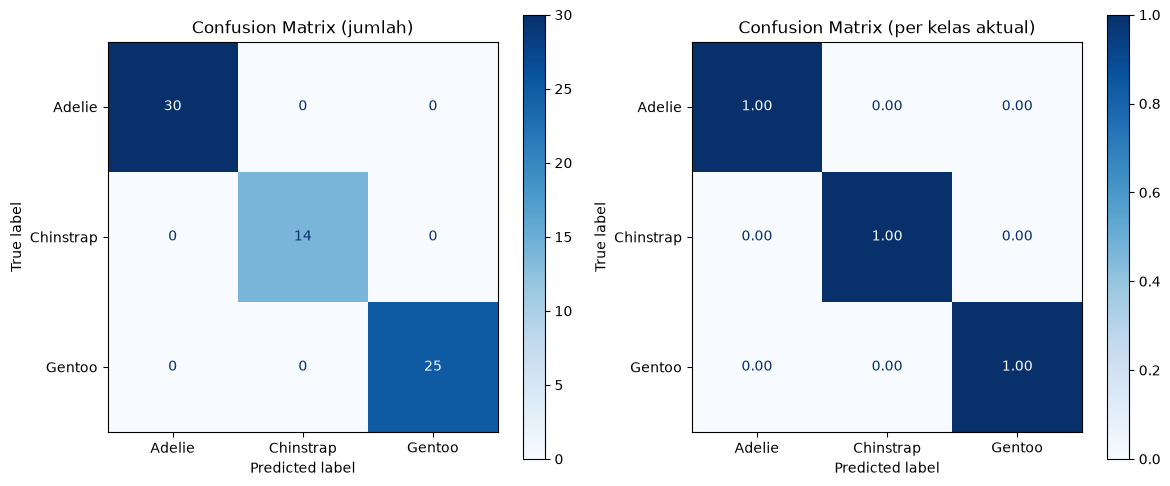

In [11]:
nama_terbaik = hasil_test.index[0]
terbaik = fitted[nama_terbaik]
pred = terbaik.predict(X_test)

print("Model terbaik:", nama_terbaik)
print(classification_report(y_test, pred, target_names=nama_kelas, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=nama_kelas,
                                        cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion Matrix (jumlah)")
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=nama_kelas,
                                        cmap="Blues", normalize="true",
                                        values_format=".2f", ax=axes[1])
axes[1].set_title("Confusion Matrix (per kelas aktual)")
plt.tight_layout()
plt.show()

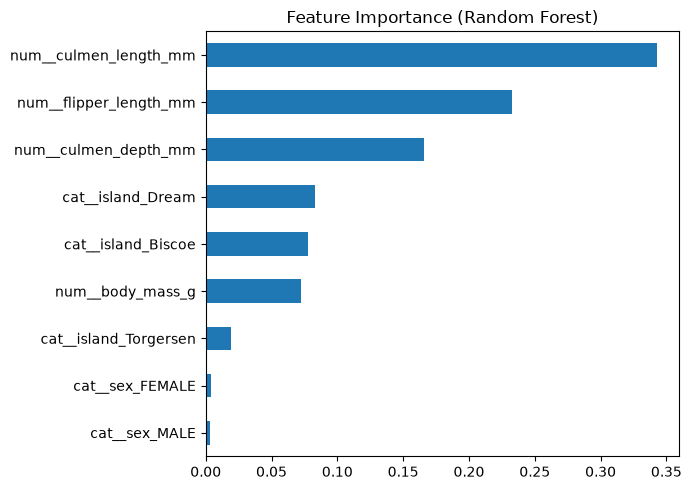

In [12]:
rf = fitted["Random Forest"]
nama_fitur = rf.named_steps["prep"].get_feature_names_out()
penting = pd.Series(rf.named_steps["clf"].feature_importances_, index=nama_fitur).sort_values()

plt.figure(figsize=(7, 5))
penting.plot(kind="barh")
plt.title("Feature Importance (Random Forest)")
plt.tight_layout()
plt.show()

In [13]:
contoh = X_test.head(5)
hasil = pd.DataFrame({
    "aktual": le.inverse_transform(y_test.head(5)),
    "prediksi": le.inverse_transform(terbaik.predict(contoh)),
}, index=contoh.index)
display(hasil)

import joblib
joblib.dump({"model": terbaik, "label_encoder": le}, "model_penguins.pkl")
print("Model tersimpan: model_penguins.pkl")

,aktual,prediksi
150,Adelie,Adelie
1,Adelie,Adelie
293,Gentoo,Gentoo
335,Gentoo,Gentoo
157,Chinstrap,Chinstrap


Model tersimpan: model_penguins.pkl
